In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/bank_defaulter_clean.csv")

In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
df = pd.read_csv("../data/bank_defaulter_clean.csv")
print("Shape:" , df.shape)
df.head()

Shape: (10000, 24)


,customer_id,age,employment_type,annual_income,credit_score,loan_amount,loan_tenure_months,existing_loans,monthly_debt,monthly_expenses,...,previous_defaults,credit_utilization,debt_to_income_ratio,savings_balance,transaction_frequency,loan_to_income_ratio,default,log_income,log_loan_amount,log_savings
0,CUST107401,50.0,Self-Employed,1416179.0,801.0,1912638.0,72,0,9520.0,54646.0,...,0,0.376,0.306,432930.0,36.0,1.351,0,14.163474,14.463995,12.978334
1,CUST105834,33.0,Salaried,145133.0,806.0,272730.0,36,2,3792.0,5000.0,...,1,0.253,0.940,49185.0,39.0,1.879,0,11.885413,12.516241,10.803364
2,CUST102122,27.0,Business,1168056.0,674.0,2579975.0,60,2,41375.0,30877.0,...,0,0.169,0.867,35759.0,66.0,2.209,0,13.970852,14.763291,10.484585
3,CUST108788,21.0,Self-Employed,252600.0,684.0,170174.0,36,0,5473.0,10809.0,...,0,0.210,0.485,14747.0,19.0,0.674,0,12.439566,12.044583,9.598863
4,CUST100304,34.0,Salaried,373981.0,654.0,1015630.0,48,1,3471.0,21945.0,...,0,0.295,0.790,34814.0,52.0,2.716,0,12.831963,13.831021,10.457804


In [5]:
df["default"].value_counts()

default
0    7050
1    2950
Name: count, dtype: int64

In [6]:
df["default"].value_counts(normalize=True) * 100

default
0    70.5
1    29.5
Name: proportion, dtype: float64

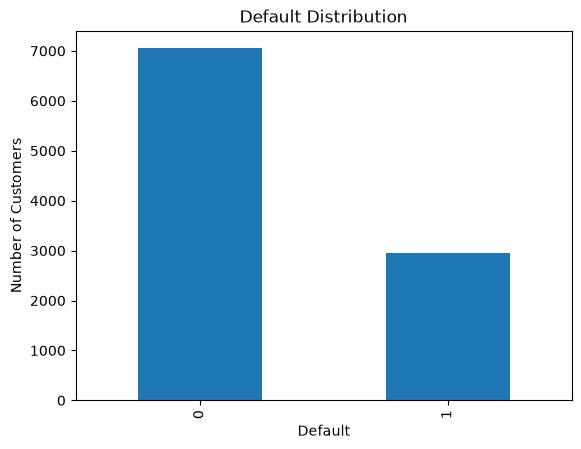

In [7]:
import matplotlib.pyplot as plt

df["default"].value_counts().plot(
    kind="bar",
    title="Default Distribution"
)

plt.xlabel("Default")
plt.ylabel("Number of Customers")
plt.show()

In [8]:
%pip install matplotlib



Note: you may need to restart the kernel to use updated packages.


In [9]:
import matplotlib.pyplot as plt

print("Matplotlib is working!")

Matplotlib is working!


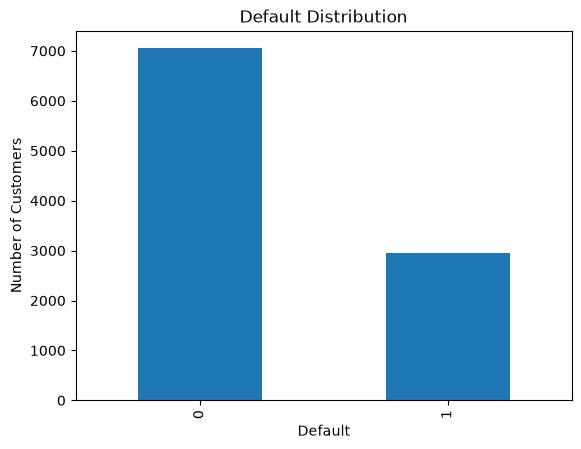

In [10]:
df["default"].value_counts().plot(
    kind="bar",
    title="Default Distribution"
)

plt.xlabel("Default")
plt.ylabel("Number of Customers")
plt.show()

Dataset shape: (10000, 24)

Target distribution:
default
0    7050
1    2950
Name: count, dtype: int64

Target percentage:
default
0    70.5
1    29.5
Name: proportion, dtype: float64


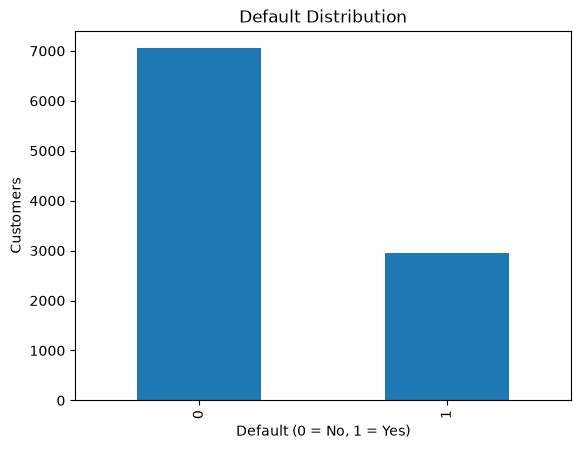


Credit Score by Default:
default
0    695.607092
1    673.694915
Name: credit_score, dtype: float64


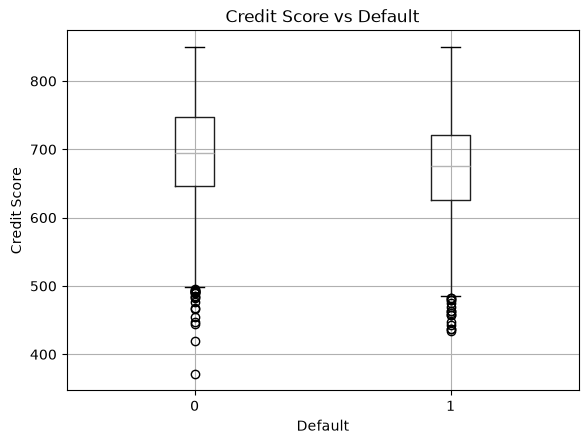


DTI by Default:
default
0    0.699543
1    1.076481
Name: debt_to_income_ratio, dtype: float64


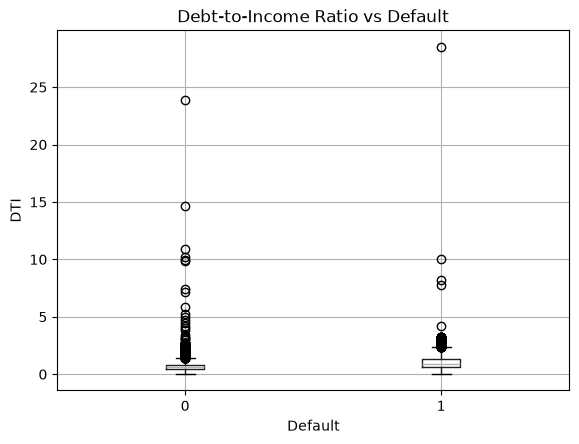


Missed payments by Default:
default
0    0.633050
1    0.917288
Name: missed_payments_last_year, dtype: float64


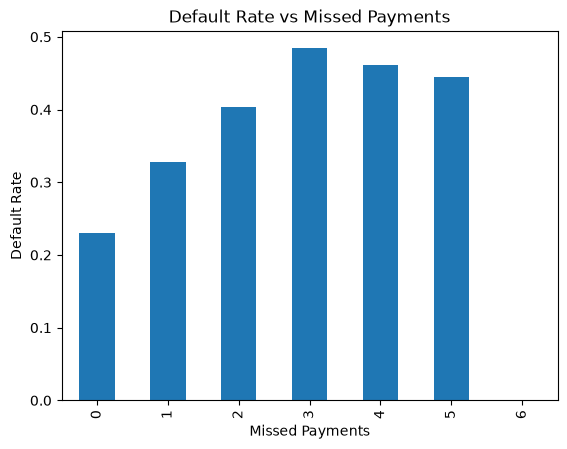


Default rate by previous default:
previous_defaults
0    0.276307
1    0.573016
Name: default, dtype: float64


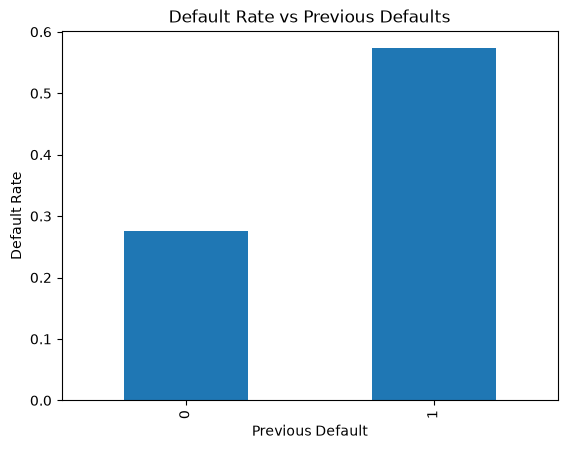


Default rate by employment type:
employment_type
Business         29.92
Salaried         29.32
Self-Employed    26.90
Unemployed       39.84
Name: default, dtype: float64


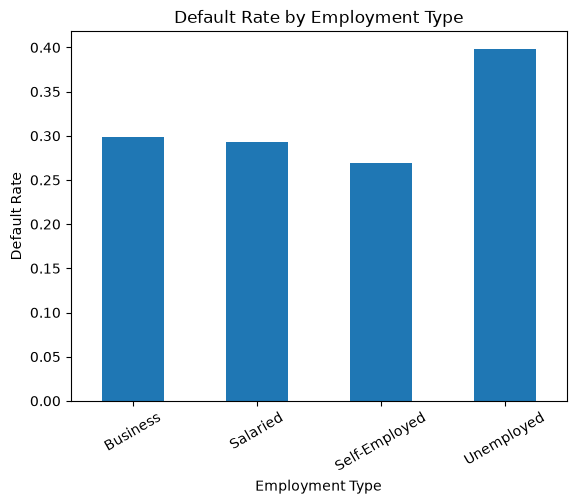


Correlation with default:
default                      1.000000
debt_to_income_ratio         0.255434
previous_defaults            0.158075
missed_payments_last_year    0.153841
log_loan_amount              0.098513
credit_utilization           0.091253
loan_to_income_ratio         0.072832
monthly_debt                 0.047228
loan_amount                  0.039802
annual_income                0.021825
employment_years             0.011446
age                          0.007118
num_credit_cards             0.006271
bank_account_age_years      -0.002913
transaction_frequency       -0.004103
existing_loans              -0.007753
log_income                  -0.017559
monthly_expenses            -0.025620
savings_balance             -0.035704
log_savings                 -0.036788
credit_score                -0.135837
loan_tenure_months          -0.222976
Name: default, dtype: float64


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned data
df = pd.read_csv("../data/bank_defaulter_clean.csv")

print("Dataset shape:", df.shape)

# =========================
# 1. TARGET DISTRIBUTION
# =========================
print("\nTarget distribution:")
print(df["default"].value_counts())

print("\nTarget percentage:")
print((df["default"].value_counts(normalize=True) * 100).round(2))

df["default"].value_counts().plot(kind="bar")
plt.title("Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Customers")
plt.show()


# =========================
# 2. CREDIT SCORE
# =========================
print("\nCredit Score by Default:")
print(df.groupby("default")["credit_score"].mean())

df.boxplot(column="credit_score", by="default")
plt.title("Credit Score vs Default")
plt.suptitle("")
plt.xlabel("Default")
plt.ylabel("Credit Score")
plt.show()


# =========================
# 3. DEBT-TO-INCOME RATIO
# =========================
print("\nDTI by Default:")
print(df.groupby("default")["debt_to_income_ratio"].mean())

df.boxplot(column="debt_to_income_ratio", by="default")
plt.title("Debt-to-Income Ratio vs Default")
plt.suptitle("")
plt.xlabel("Default")
plt.ylabel("DTI")
plt.show()


# =========================
# 4. MISSED PAYMENTS
# =========================
print("\nMissed payments by Default:")
print(df.groupby("default")["missed_payments_last_year"].mean())

missed_default = df.groupby(
    "missed_payments_last_year"
)["default"].mean()

missed_default.plot(kind="bar")
plt.title("Default Rate vs Missed Payments")
plt.xlabel("Missed Payments")
plt.ylabel("Default Rate")
plt.show()


# =========================
# 5. PREVIOUS DEFAULTS
# =========================
print("\nDefault rate by previous default:")
print(df.groupby("previous_defaults")["default"].mean())

df.groupby("previous_defaults")["default"].mean().plot(kind="bar")
plt.title("Default Rate vs Previous Defaults")
plt.xlabel("Previous Default")
plt.ylabel("Default Rate")
plt.show()


# =========================
# 6. EMPLOYMENT TYPE
# =========================
employment_rate = df.groupby(
    "employment_type"
)["default"].mean()

print("\nDefault rate by employment type:")
print((employment_rate * 100).round(2))

employment_rate.plot(kind="bar")
plt.title("Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate")
plt.xticks(rotation=30)
plt.show()


# =========================
# 7. CORRELATION WITH TARGET
# =========================
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()["default"].sort_values(
    ascending=False
)

print("\nCorrelation with default:")
print(correlation)

In [12]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [13]:
import sklearn

print(sklearn.__version__)

1.5.2


In [14]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["customer_id", "default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 22)
Testing: (2000, 22)


In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["customer_id", "default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 22)
Testing: (2000, 22)


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_features = ["employment_type"]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [17]:
import sklearn
print(sklearn.__version__)


1.5.2


In [18]:
from sklearn.model_selection import train_test_split
print("train_test_split OK")

train_test_split OK


In [19]:
from sklearn.preprocessing import StandardScaler
print("StandardScaler OK")


StandardScaler OK


In [20]:
from sklearn.linear_model import LogisticRegression
print("LogisticRegression OK")

LogisticRegression OK


In [21]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression is working!")

Logistic Regression is working!


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = ["employment_type"]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


e:\HCL\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.71
Precision: 0.5065
Recall   : 0.6593
F1 Score : 0.5729
ROC-AUC  : 0.7632

Confusion Matrix:
[[1031  379]
 [ 201  389]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.73      0.78      1410
           1       0.51      0.66      0.57       590

    accuracy                           0.71      2000
   macro avg       0.67      0.70      0.68      2000
weighted avg       0.74      0.71      0.72      2000



In [24]:

from sklearn.tree import DecisionTreeClassifier

decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)
y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]


In [25]:
print("Decision Tree")
print("----------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall   :", round(recall_score(y_test, y_pred_dt), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_dt), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree
----------------
Accuracy : 0.725
Precision: 0.5329
Recall   : 0.5492
F1 Score : 0.5409
ROC-AUC  : 0.7243

Confusion Matrix:
[[1126  284]
 [ 266  324]]


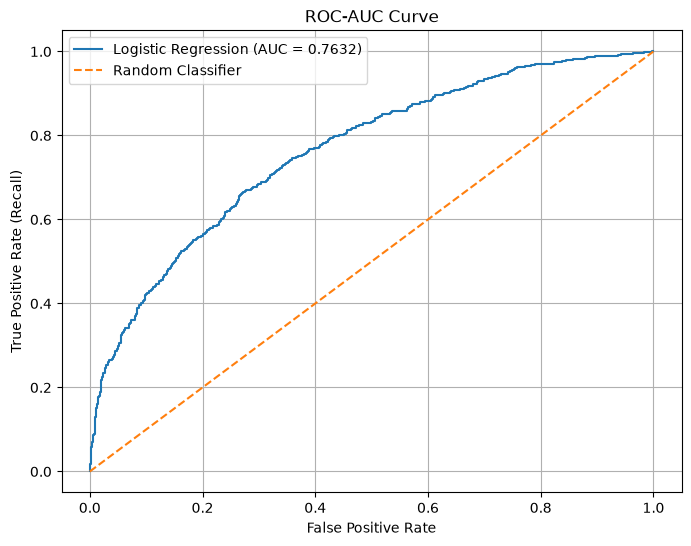

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-AUC Curve")
plt.legend()
plt.grid()
plt.show()

In [27]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

In [28]:
print("Random Forest")
print("----------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest
----------------
Accuracy : 0.7315
Precision: 0.5509
Recall   : 0.4864
F1 Score : 0.5167
ROC-AUC  : 0.7449

Confusion Matrix:
[[1176  234]
 [ 303  287]]


In [29]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_results.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7100,0.5065,0.6593,0.5729,0.7632
1,Decision Tree,0.7250,0.5329,0.5492,0.5409,0.7243
2,Random Forest,0.7315,0.5509,0.4864,0.5167,0.7449


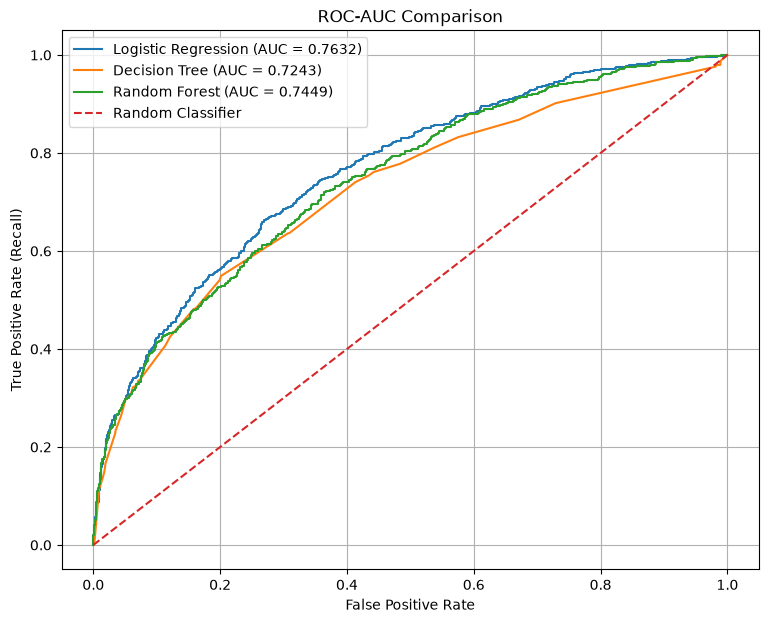

In [30]:
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_lr = roc_auc_score(y_test, y_prob)
auc_dt = roc_auc_score(y_test, y_prob_dt)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_lr, tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.4f})"
)

plt.plot(
    fpr_dt, tpr_dt,
    label=f"Decision Tree (AUC = {auc_dt:.4f})"
)

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-AUC Comparison")
plt.legend()
plt.grid()
plt.show()

In [31]:
# Get feature names after preprocessing
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Coefficient": abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Absolute_Coefficient
14,numeric__debt_to_income_ratio,1.234447,1.234447
17,numeric__loan_to_income_ratio,-0.953612,0.953612
19,numeric__log_loan_amount,0.598133,0.598133
24,categorical__employment_type_Unemployed,0.509026,0.509026
2,numeric__credit_score,-0.401103,0.401103
12,numeric__previous_defaults,0.357555,0.357555
11,numeric__missed_payments_last_year,0.356715,0.356715
18,numeric__log_income,-0.292124,0.292124
23,categorical__employment_type_Self-Employed,-0.287017,0.287017
13,numeric__credit_utilization,0.271247,0.271247


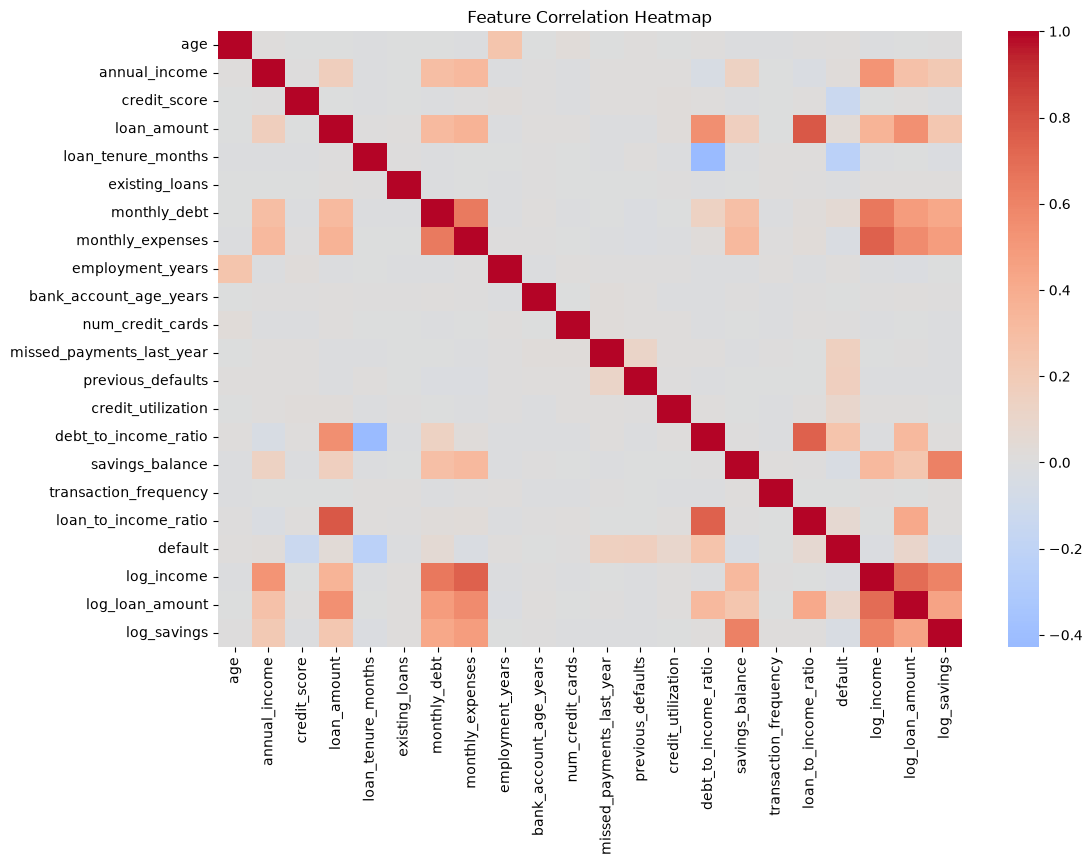

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [33]:
model_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7100,0.5065,0.6593,0.5729,0.7632
1,Decision Tree,0.7250,0.5329,0.5492,0.5409,0.7243
2,Random Forest,0.7315,0.5509,0.4864,0.5167,0.7449


In [34]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 8, 12, 16],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters:
{'model__max_depth': 8, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.7557


In [35]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

print("Tuned Random Forest")
print("-------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf_tuned), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf_tuned), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_rf_tuned), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf_tuned), 4))

Tuned Random Forest
-------------------
Accuracy : 0.727
Precision: 0.5362
Recall   : 0.5525
F1 Score : 0.5442
ROC-AUC  : 0.7545


In [36]:
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train, y_train)

print("Best Parameters:")
print(lr_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(lr_grid.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:
{'model__C': 0.1, 'model__solver': 'liblinear'}

Best Cross-Validation ROC-AUC:
0.7661


In [37]:
best_lr = lr_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test)
y_prob_lr_tuned = best_lr.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression")
print("-------------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_lr_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr_tuned), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr_tuned), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_lr_tuned), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_lr_tuned), 4))

Tuned Logistic Regression
-------------------------
Accuracy : 0.709
Precision: 0.5052
Recall   : 0.6627
F1 Score : 0.5733
ROC-AUC  : 0.7626


In [38]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_lr_tuned >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1 Score": f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1 Score
0,0.20,0.3291,0.9746,0.4921
1,0.25,0.3503,0.9475,0.5114
2,0.30,0.3677,0.9068,0.5232
3,0.35,0.3991,0.8576,0.5447
4,0.40,0.4295,0.8000,0.5589
5,0.45,0.4648,0.7390,0.5707
6,0.50,0.5052,0.6627,0.5733
7,0.55,0.5333,0.5695,0.5508
8,0.60,0.5786,0.5051,0.5394
9,0.65,0.6143,0.4373,0.5109


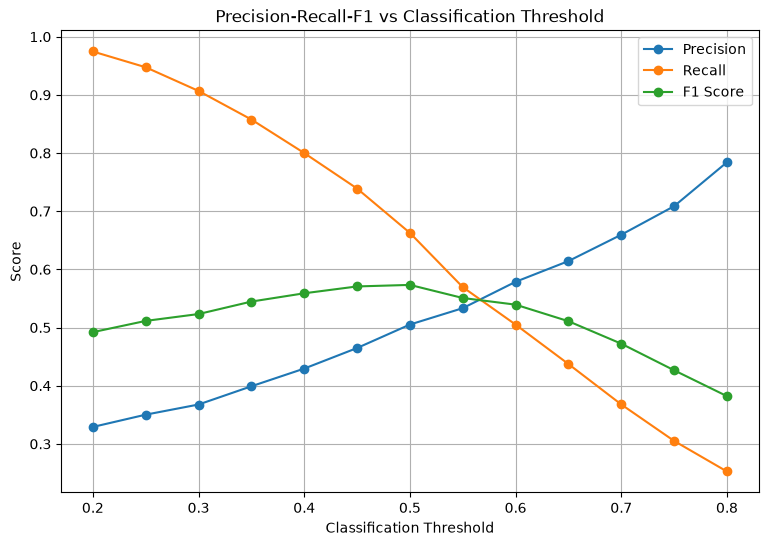

In [39]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall-F1 vs Classification Threshold")
plt.legend()
plt.grid()
plt.show()

In [40]:
best_f1_row = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

print("Best threshold based on F1:")
print(best_f1_row)

Best threshold based on F1:
Threshold    0.500000
Precision    0.505168
Recall       0.662712
F1 Score     0.573314
Name: 6, dtype: float64


In [41]:
best_threshold = best_f1_row["Threshold"]

y_pred_final = (
    y_prob_lr_tuned >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Selected Threshold: 0.49999999999999994

Confusion Matrix:
[[1027  383]
 [ 199  391]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.73      0.78      1410
           1       0.51      0.66      0.57       590

    accuracy                           0.71      2000
   macro avg       0.67      0.70      0.68      2000
weighted avg       0.74      0.71      0.72      2000



In [42]:
%pip install joblib
%pip install os

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement os (from versions: none)
ERROR: No matching distribution found for os


In [44]:
import os
import joblib

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained pipeline
joblib.dump(
    best_lr,
    "../models/bank_defaulter_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [45]:
import os

print(os.path.exists("../models/bank_defaulter_model.pkl"))

True


In [46]:
import joblib

model = joblib.load("../models/bank_defaulter_model.pkl")

print("Model loaded successfully!")
print(model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'annual_income',
                                                   'credit_score',
                                                   'loan_amount',
                                                   'loan_tenure_months',
                                                   'existing_loans',
                                                   'monthly_debt',
                                                   'monthly_expenses',
                                              

In [47]:
sample = X_test.iloc[[0]]

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0][1]

print("Prediction:", prediction)
print("Default Probability:", round(probability * 100, 2), "%")

Prediction: 1
Default Probability: 72.02 %


In [49]:
%pip install streamlit

   ---------------------------------------- 0.0/10.1 MB ? eta -:--:--
   ------------- -------------------------- 3.4/10.1 MB 17.4 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/10.1 MB 18.4 MB/s eta 0:00:01
   ---------------------------------------- 10.1/10.1 MB 17.5 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 14.2 MB/s  0:00:00
   ---------------------------------------- 0.0/27.9 MB ? eta -:--:--
   --- ------------------------------------ 2.6/27.9 MB 12.6 MB/s eta 0:00:03
   -------- ------------------------------- 5.8/27.9 MB 14.4 MB/s eta 0:00:02
   ------------- -------------------------- 9.4/27.9 MB 15.6 MB/s eta 0:00:02
   ------------------ --------------------- 13.1/27.9 MB 16.3 MB/s eta 0:00:01
   ------------------------ --------------- 16.8/27.9 MB 16.5 MB/s eta 0:00:01
   ---------------------------- ----------- 20.2/27.9 MB 16.7 MB/s eta 0:00:01
   -----

In [51]:
import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("../models/bank_defaulter_model.pkl")

In [52]:
customer_data = {
    "age": age,
    "employment_type": employment_type,
    "annual_income": annual_income,
    "credit_score": credit_score,
    "loan_amount": loan_amount,
    "loan_tenure_months": loan_tenure_months,
    "existing_loans": existing_loans,
    "monthly_debt": monthly_debt,
    "monthly_expenses": monthly_expenses,
    "employment_years": employment_years,
    "bank_account_age_years": bank_account_age_years,
    "num_credit_cards": num_credit_cards,
    "missed_payments_last_year": missed_payments_last_year,
    "previous_defaults": previous_defaults,
    "credit_utilization": credit_utilization,
    "debt_to_income_ratio": debt_to_income_ratio,
    "savings_balance": savings_balance,
    "transaction_frequency": transaction_frequency,
    "loan_to_income_ratio": loan_to_income_ratio,
    "log_income": log_income,
    "log_loan_amount": log_loan_amount,
    "log_savings": log_savings
}

input_df = pd.DataFrame([customer_data])

NameError: name 'age' is not defined

In [53]:
# Take one customer from the test set
sample = X_test.iloc[[0]]

print(sample)

       age employment_type  annual_income  credit_score  loan_amount  \
8658  28.0        Salaried      1139821.0         560.0    1740381.0   

      loan_tenure_months  existing_loans  monthly_debt  monthly_expenses  \
8658                  36               2       30544.0           28719.0   

      employment_years  ...  missed_payments_last_year  previous_defaults  \
8658               4.3  ...                          1                  0   

      credit_utilization  debt_to_income_ratio  savings_balance  \
8658               0.349                 0.831         128283.0   

      transaction_frequency  loan_to_income_ratio  log_income  \
8658                   18.0                 1.527   13.946383   

      log_loan_amount  log_savings  
8658        14.369615    11.762002  

[1 rows x 22 columns]


In [54]:
prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0][1]

print("Prediction:", prediction)
print("Default Probability:", round(probability * 100, 2), "%")

Prediction: 1
Default Probability: 72.02 %
